# Financial AI GPT — Baseline (10 Epochs)

금융 AI·환각·RAG 관련 한국어 텍스트를 대상으로 **GPT를 무작위 초기화하여 훈련**한 기준 실험.

- 실험 조건: 21,360바이트 / 18,253 GPT-2 토큰, 학습/검증 90:10, CUDA, AdamW, 10에포크
- 결과: 최저 검증 손실 약 2.683(Step 100), 10에포크 마지막 검증 손실 4.039(Step 315)
- 한계: 한국어 생성 불완전. RAG/금융 챗봇 구축이나 환각 감소 실험은 수행하지 않음

> 대학원 컴퓨터특론(LLM) 수업에서 제공된 GPT 구조·훈련 코드를 바탕으로 데이터 선정 및 실험 수행. 학습 텍스트는 원문 이용조건상 GitHub에 포함하지 않음. 실행 시 직접 준비한 UTF-8 텍스트를 `/content/financial_ai_hallucination.txt`에 업로드 필요. 다른 텍스트 사용 시 저장된 손실 수치의 재현은 보장되지 않음.

## 0. 환경 준비

Colab에서 실행 시 필요한 패키지를 설치합니다 (로컬에 이미 있으면 빠르게 넘어갑니다).

In [14]:
# Colab 환경 준비
!pip install -q torch tiktoken matplotlib

### 과제용 학습 데이터 준비

기존 실습의 `the-verdict.txt` 대신 **`financial_ai_hallucination.txt`** 파일 사용.

코랩 좌측 **파일 → 업로드**에서 해당 텍스트 파일을 `/content/`에 업로드한 후, 5.1.3의 데이터 읽기 셀 실행.

> 이 셀은 원래 소설을 자동 다운로드하던 예제였으나 과제 데이터로 대체하여 제거함. 재실행 시에는 `.txt` 파일을 먼저 업로드해야 함.


## 이전 챕터 코드

이 노트북은 앞 챕터에서 만든 `GPTModel`과 부품, 데이터 로더가 모두 필요합니다. 아래 셀들은 **재정의일 뿐**이니
내용을 자세히 볼 필요 없이 그대로 실행하고 넘어가세요.

- `GPT_CONFIG_124M`: GPT-2 124M 설정 딕셔너리 (단, **문맥 길이만 1024 → 256으로 축소**, 원본 5.1.1절)
- `MultiHeadAttention`: 마스크드 멀티 헤드 어텐션 (ch05, 원본 3장)
- `LayerNorm` / `GELU` / `FeedForward`: 층 정규화·활성화·피드 포워드 (ch06, 원본 4.2~4.3절)
- `TransformerBlock` / `GPTModel` / `generate_text_simple`: 트랜스포머 블록·GPT 모델·생성 함수 (ch07, 원본 4.5~4.7절)
- `GPTDatasetV1` / `create_dataloader_v1`: 슬라이딩 윈도 데이터셋·데이터 로더 (ch03, 원본 2장)

In [15]:
# 공통 임포트 + GPT-2 124M 설정 딕셔너리 (문맥 길이만 256으로 축소)
import torch
import torch.nn as nn
import tiktoken

GPT_CONFIG_124M = {
    "vocab_size": 50257,     # 어휘사전 크기
    "context_length": 256,   # 문맥 길이 (원본 4장의 1024 -> 256으로 축소해 훈련 자원 절감)
    "emb_dim": 768,          # 임베딩 차원
    "n_heads": 12,           # 어텐션 헤드 개수
    "n_layers": 12,          # 층 개수
    "drop_rate": 0.1,        # 드롭아웃 비율
    "qkv_bias": False,       # 쿼리, 키, 값 계산을 위한 편향
}
print("설정 준비 완료:", GPT_CONFIG_124M)

설정 준비 완료: {'vocab_size': 50257, 'context_length': 256, 'emb_dim': 768, 'n_heads': 12, 'n_layers': 12, 'drop_rate': 0.1, 'qkv_bias': False}


In [16]:
# [ch05 재정의] 마스크드 멀티 헤드 어텐션
class MultiHeadAttention(nn.Module):
    def __init__(self, d_in, d_out,
                 context_length, dropout, num_heads, qkv_bias=False):
        super().__init__()
        assert (d_out % num_heads == 0), \
            "d_out은 num_heads로 나누어 떨어져야 합니다"

        self.d_out = d_out
        self.num_heads = num_heads
        self.head_dim = d_out // num_heads   # 출력 차원에 맞춰 헤드별 투영 차원
        self.W_query = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_key = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.W_value = nn.Linear(d_in, d_out, bias=qkv_bias)
        self.out_proj = nn.Linear(d_out, d_out)   # 헤드 출력을 결합하는 선형 층
        self.dropout = nn.Dropout(dropout)
        self.register_buffer(
            "mask",
            torch.triu(torch.ones(context_length, context_length),
                       diagonal=1)
        )

    def forward(self, x):
        b, num_tokens, d_in = x.shape
        keys = self.W_key(x)
        queries = self.W_query(x)
        values = self.W_value(x)

        # (b, num_tokens, d_out) -> (b, num_tokens, num_heads, head_dim)
        keys = keys.view(b, num_tokens, self.num_heads, self.head_dim)
        values = values.view(b, num_tokens, self.num_heads, self.head_dim)
        queries = queries.view(b, num_tokens, self.num_heads, self.head_dim)

        # -> (b, num_heads, num_tokens, head_dim)
        keys = keys.transpose(1, 2)
        queries = queries.transpose(1, 2)
        values = values.transpose(1, 2)

        attn_scores = queries @ keys.transpose(2, 3)   # 헤드별 점곱
        mask_bool = self.mask.bool()[:num_tokens, :num_tokens]
        attn_scores.masked_fill_(mask_bool, -torch.inf)

        attn_weights = torch.softmax(
            attn_scores / keys.shape[-1]**0.5, dim=-1)
        attn_weights = self.dropout(attn_weights)

        context_vec = (attn_weights @ values).transpose(1, 2)
        context_vec = context_vec.contiguous().view(
            b, num_tokens, self.d_out)
        context_vec = self.out_proj(context_vec)   # 선형 투영
        return context_vec

print("MultiHeadAttention 정의 완료")

MultiHeadAttention 정의 완료


In [17]:
# [ch06 재정의] 층 정규화 + GELU + 피드 포워드
class LayerNorm(nn.Module):
    def __init__(self, emb_dim):
        super().__init__()
        self.eps = 1e-5
        self.scale = nn.Parameter(torch.ones(emb_dim))
        self.shift = nn.Parameter(torch.zeros(emb_dim))

    def forward(self, x):
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, keepdim=True, unbiased=False)
        norm_x = (x - mean) / torch.sqrt(var + self.eps)
        return self.scale * norm_x + self.shift


class GELU(nn.Module):
    def __init__(self):
        super().__init__()

    def forward(self, x):
        return 0.5 * x * (1 + torch.tanh(
            torch.sqrt(torch.tensor(2.0 / torch.pi)) *
            (x + 0.044715 * torch.pow(x, 3))
        ))


class FeedForward(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(cfg["emb_dim"], 4 * cfg["emb_dim"]),
            GELU(),
            nn.Linear(4 * cfg["emb_dim"], cfg["emb_dim"]),
        )

    def forward(self, x):
        return self.layers(x)

print("LayerNorm / GELU / FeedForward 정의 완료")

LayerNorm / GELU / FeedForward 정의 완료


In [18]:
# [ch07 재정의] 트랜스포머 블록 + GPT 모델 + 생성 함수
class TransformerBlock(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.att = MultiHeadAttention(
            d_in=cfg["emb_dim"],
            d_out=cfg["emb_dim"],
            context_length=cfg["context_length"],
            num_heads=cfg["n_heads"],
            dropout=cfg["drop_rate"],
            qkv_bias=cfg["qkv_bias"])
        self.ff = FeedForward(cfg)
        self.norm1 = LayerNorm(cfg["emb_dim"])
        self.norm2 = LayerNorm(cfg["emb_dim"])
        self.drop_shortcut = nn.Dropout(cfg["drop_rate"])

    def forward(self, x):
        # 어텐션 블록: 층 정규화 -> 어텐션 -> 드롭아웃 -> 숏컷 덧셈
        shortcut = x
        x = self.norm1(x)
        x = self.att(x)
        x = self.drop_shortcut(x)
        x = x + shortcut             # 원본 입력을 더합니다.

        # 피드 포워드 블록: 층 정규화 -> 피드 포워드 -> 드롭아웃 -> 숏컷 덧셈
        shortcut = x
        x = self.norm2(x)
        x = self.ff(x)
        x = self.drop_shortcut(x)
        x = x + shortcut             # 원본 입력을 더합니다.
        return x


class GPTModel(nn.Module):
    def __init__(self, cfg):
        super().__init__()
        self.tok_emb = nn.Embedding(cfg["vocab_size"], cfg["emb_dim"])
        self.pos_emb = nn.Embedding(cfg["context_length"], cfg["emb_dim"])
        self.drop_emb = nn.Dropout(cfg["drop_rate"])

        self.trf_blocks = nn.Sequential(
            *[TransformerBlock(cfg) for _ in range(cfg["n_layers"])])

        self.final_norm = LayerNorm(cfg["emb_dim"])
        self.out_head = nn.Linear(
            cfg["emb_dim"], cfg["vocab_size"], bias=False
        )

    def forward(self, in_idx):
        batch_size, seq_len = in_idx.shape
        tok_embeds = self.tok_emb(in_idx)
        pos_embeds = self.pos_emb(
            torch.arange(seq_len, device=in_idx.device)   # 입력 위치에 따라 CPU/GPU 자동 대응
        )
        x = tok_embeds + pos_embeds
        x = self.drop_emb(x)
        x = self.trf_blocks(x)
        x = self.final_norm(x)
        logits = self.out_head(x)   # 다음 토큰에 대한 정규화되지 않은 확률(로짓)
        return logits


def generate_text_simple(model, idx,      # idx: (batch, num_tokens) 크기의 현재 문맥
                         max_new_tokens, context_size):
    for _ in range(max_new_tokens):
        idx_cond = idx[:, -context_size:]  # 지원 문맥 크기 초과 시 잘라냄
        with torch.no_grad():
            logits = model(idx_cond)
        logits = logits[:, -1, :]          # 마지막 타임 스텝만: (batch, vocab_size)
        probas = torch.softmax(logits, dim=-1)                 # (batch, vocab_size)
        idx_next = torch.argmax(probas, dim=-1, keepdim=True)  # (batch, 1)
        idx = torch.cat((idx, idx_next), dim=1)                # (batch, num_tokens+1)
    return idx

print("TransformerBlock / GPTModel / generate_text_simple 정의 완료")

TransformerBlock / GPTModel / generate_text_simple 정의 완료


In [11]:
# [ch03 재정의] 데이터셋 + 데이터 로더 (슬라이딩 윈도)
from torch.utils.data import Dataset, DataLoader

class GPTDatasetV1(Dataset):
    def __init__(self, txt, tokenizer, max_length, stride):
        self.input_ids = []
        self.target_ids = []
        token_ids = tokenizer.encode(txt, allowed_special={"<|endoftext|>"})
        for i in range(0, len(token_ids) - max_length, stride):
            input_chunk = token_ids[i:i + max_length]
            target_chunk = token_ids[i + 1: i + max_length + 1]
            self.input_ids.append(torch.tensor(input_chunk))
            self.target_ids.append(torch.tensor(target_chunk))

    def __len__(self):
        return len(self.input_ids)

    def __getitem__(self, idx):
        return self.input_ids[idx], self.target_ids[idx]


def create_dataloader_v1(txt, batch_size=4, max_length=256,
                         stride=128, shuffle=True, drop_last=True,
                         num_workers=0):
    tokenizer = tiktoken.get_encoding("gpt2")
    dataset = GPTDatasetV1(txt, tokenizer, max_length, stride)
    dataloader = DataLoader(
        dataset, batch_size=batch_size, shuffle=shuffle,
        drop_last=drop_last, num_workers=num_workers)
    return dataloader

print("GPTDatasetV1 / create_dataloader_v1 정의 완료")

GPTDatasetV1 / create_dataloader_v1 정의 완료


## 5.1.1 GPT를 사용해 텍스트 생성하기

### 모델 초기화
`GPTModel`을 초기화합니다. ch07과의 차이는 문맥 길이(`context_length`)를
1,024에서 256으로 줄인 것뿐입니다(훈련에 드는 계산 자원 절감). `model.eval()`로 드롭아웃을 끕니다.

In [25]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)   # 163M 파라미터 초기화 — CPU에서 수 초 걸릴 수 있습니다
model.eval()
print("모델 초기화 완료 (문맥 길이:", GPT_CONFIG_124M["context_length"], ")")

모델 초기화 완료 (문맥 길이: 256 )


### 텍스트 생성 사이클: 텍스트 → 토큰 ID → 로짓 → 텍스트

텍스트를 토큰 ID로 바꾸고(`text_to_token_ids`), 모델이 만든 토큰 ID를 다시 텍스트로
디코딩하는(`token_ids_to_text`) 유틸리티 함수를 만듭니다. 이 장 내내 재사용합니다.

In [26]:
# 리스팅 5.1 — 텍스트 ↔ 토큰 ID 변환 유틸리티
def text_to_token_ids(text, tokenizer):
    encoded = tokenizer.encode(text, allowed_special={'<|endoftext|>'})
    encoded_tensor = torch.tensor(encoded).unsqueeze(0)  # 배치 차원 추가
    return encoded_tensor


def token_ids_to_text(token_ids, tokenizer):
    flat = token_ids.squeeze(0)  # 배치 차원 제거
    return tokenizer.decode(flat.tolist())


start_context = "Every effort moves you"
tokenizer = tiktoken.get_encoding("gpt2")

token_ids = generate_text_simple(
    model=model,
    idx=text_to_token_ids(start_context, tokenizer),
    max_new_tokens=10,
    context_size=GPT_CONFIG_124M["context_length"]
)
print("출력 텍스트:\n", token_ids_to_text(token_ids, tokenizer))

출력 텍스트:
 Every effort moves you rentingetic wasnم refres RexMeCHicular stren


## 5.1.3 훈련 세트와 검증 세트의 손실 계산하기

### 훈련 데이터셋 : 금융 AI 챗봇의 환각 문제와 RAG 기반 대응

NIA RAG 기술 보고서와 금융위원회 보도자료에서 금융 AI, 환각, RAG 관련 본문을 추출·정리한 UTF-8 텍스트 사용.

- **파일명 :** `financial_ai_hallucination.txt`
- **파일 크기 :** 21,360바이트
- **문자 수 :** 9,249자
- **GPT-2 토큰 수 :** 18,253개

학습 데이터에 RAG의 개념과 금융 AI 적용 사례가 포함되어 있으나, **실습 내용은 RAG 구현이 아닌 GPT의 다음 토큰 예측 학습**임.


In [8]:
import tiktoken
tokenizer = tiktoken.get_encoding("gpt2")

file_path = "/content/financial_ai_hallucination.txt"

with open(file_path, "r", encoding="utf-8") as file:
    text_data = file.read()

total_characters = len(text_data)
total_tokens = len(tokenizer.encode(text_data))

print("문자 수:", total_characters)
print("토큰 수:", total_tokens)

문자 수: 9249
토큰 수: 18253


### 9:1 분할과 데이터 로더 생성

`train_ratio=0.90`으로 훈련 세트 90%, 검증 세트 10%로 나눕니다.
`max_length`와 `stride`를 모두 문맥 길이(256)로 맞춰 겹치지 않게 자릅니다.
검증 로더는 `drop_last=False`, `shuffle=False`로 설정합니다.

In [19]:
import torch

train_ratio = 0.90
split_idx = int(train_ratio * len(text_data))
train_data = text_data[:split_idx]
val_data = text_data[split_idx:]

torch.manual_seed(123)

# 아래 기존 train_loader, val_loader 코드는 그대로 유지

train_loader = create_dataloader_v1(
    train_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=True,
    shuffle=True,
    num_workers=0
)
val_loader = create_dataloader_v1(
    val_data,
    batch_size=2,
    max_length=GPT_CONFIG_124M["context_length"],
    stride=GPT_CONFIG_124M["context_length"],
    drop_last=False,
    shuffle=False,
    num_workers=0
)
print("데이터 로더 생성 완료")

데이터 로더 생성 완료


### 데이터 로더 확인 : 배치 차원

문자 위치를 기준으로 원문을 90:10으로 분할한 뒤 GPT-2 토크나이저로 토큰화함.

실제 출력에서 **훈련 배치 32개, 검증 배치 4개** 확인. 배치는 대부분 `[2, 256]` 형태이며 마지막 검증 배치는 `[1, 256]`임.


In [20]:
print("훈련 데이터 로더:")
for x, y in train_loader:
    print(x.shape, y.shape)

print("\n검증 데이터 로더:")
for x, y in val_loader:
    print(x.shape, y.shape)

훈련 데이터 로더:
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) torch.Size([2, 256])
torch.Size([2, 256]) to

### 배치 하나의 손실: calc_loss_batch

입력·타깃 배치를 지정 장치(`device`)로 보낸 뒤, 로짓을 계산하고 `flatten`한 뒤 `cross_entropy`로
스칼라 손실을 반환합니다(5.1.2절과 동일한 계산). `device`를 쓰므로 GPU 사용 시에도 코드 수정이 필요 없습니다.

In [21]:
def calc_loss_batch(input_batch, target_batch, model, device):
    input_batch = input_batch.to(device)
    target_batch = target_batch.to(device)
    logits = model(input_batch)
    loss = torch.nn.functional.cross_entropy(
        logits.flatten(0, 1), target_batch.flatten()
    )
    return loss

print("calc_loss_batch 정의 완료")

calc_loss_batch 정의 완료


### 전체 로더의 손실: calc_loss_loader

데이터 로더의 모든 배치를 순회하며 손실을 누적한 뒤 배치 개수로 평균합니다.
`num_batches`를 지정하면 앞쪽 일부 배치만 평가해 속도를 높일 수 있습니다(훈련 중 평가에 활용).

In [22]:
# 리스팅 5.2 — 훈련 손실과 검증 손실을 계산하는 함수
def calc_loss_loader(data_loader, model, device, num_batches=None):
    total_loss = 0.
    if len(data_loader) == 0:
        return float("nan")
    elif num_batches is None:
        num_batches = len(data_loader)   # 미지정 시 전체 배치 순회
    else:
        num_batches = min(num_batches, len(data_loader))
    for i, (input_batch, target_batch) in enumerate(data_loader):
        if i < num_batches:
            loss = calc_loss_batch(input_batch, target_batch, model, device)
            total_loss += loss.item()   # 각 배치의 손실을 누적
        else:
            break
    return total_loss / num_batches   # 모든 배치의 손실을 평균

print("calc_loss_loader 정의 완료")

calc_loss_loader 정의 완료


### 훈련 전 초기 손실

무작위 초기화 모델의 훈련 전 손실 측정 결과 :

- **장치 :** CUDA
- **훈련 손실 :** 11.0142
- **검증 손실 :** 10.9930

초기 손실이 높고 훈련·검증 손실이 유사한 상태로, 아직 해당 데이터에 대한 학습이 진행되지 않았음을 확인.


In [27]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
model.to(device)
with torch.no_grad():   # 훈련이 아니므로 그레이디언트 추적을 끕니다.
    train_loss = calc_loss_loader(train_loader, model, device)
    val_loss = calc_loss_loader(val_loader, model, device)
print("사용 장치:", device)
print("훈련 손실:", train_loss)
print("검증 손실:", val_loss)

사용 장치: cuda
훈련 손실: 11.014228880405426
검증 손실: 10.993030071258545


## 5.2 LLM 훈련하기

### 전형적인 파이토치 훈련 루프: 8단계

1. 에포크 루프 (num_epochs 반복)
2. 배치 루프 (train_loader 순회)
3. `optimizer.zero_grad()` — 이전 그레이디언트 초기화
4. `loss = calc_loss_batch(...)` — 현재 배치 손실
5. `loss.backward()` — 역전파로 그레이디언트 계산
6. `optimizer.step()` — 가중치 업데이트
7. `eval_freq` 스텝마다 훈련·검증 손실 평가·출력
8. 에포크 종료 시 샘플 텍스트 생성

`train_model_simple`이 이 8단계를 구현합니다(리스팅 5.3).

In [28]:
# 리스팅 5.3 — LLM 사전 훈련 함수
def train_model_simple(model, train_loader, val_loader,
                       optimizer, device, num_epochs,
                       eval_freq, eval_iter, start_context, tokenizer):
    # 손실과 지금까지 처리한 토큰 수 추적용 리스트
    train_losses, val_losses, track_tokens_seen = [], [], []
    tokens_seen, global_step = 0, -1

    for epoch in range(num_epochs):        # 1) 에포크 루프
        model.train()
        for input_batch, target_batch in train_loader:   # 2) 배치 루프
            optimizer.zero_grad()          # 3) 그레이디언트 초기화
            loss = calc_loss_batch(        # 4) 현재 배치 손실
                input_batch, target_batch, model, device)
            loss.backward()                # 5) 역전파
            optimizer.step()               # 6) 가중치 업데이트
            tokens_seen += input_batch.numel()
            global_step += 1

            if global_step % eval_freq == 0:   # 7) 평가·출력 단계
                train_loss, val_loss = evaluate_model(
                    model, train_loader, val_loader, device, eval_iter)
                train_losses.append(train_loss)
                val_losses.append(val_loss)
                track_tokens_seen.append(tokens_seen)
                print(f"에포크 {epoch+1} (Step {global_step:06d}): "
                      f"훈련 손실 {train_loss:.3f}, "
                      f"검증 손실 {val_loss:.3f}")

        generate_and_print_sample(         # 8) 에포크 후 샘플 텍스트 생성
            model, tokenizer, device, start_context
        )

    return train_losses, val_losses, track_tokens_seen

print("train_model_simple 정의 완료")

train_model_simple 정의 완료


### 보조 함수: evaluate_model과 generate_and_print_sample

- `evaluate_model`: 평가 모드로 드롭아웃과 그레이디언트 추적을 끄고, 훈련·검증 손실을 각각 `eval_iter`개 배치로 빠르게 계산
- `generate_and_print_sample`: `start_context`로 50개 토큰을 생성해 품질을 눈으로 확인 (문맥 크기는 `model.pos_emb.weight.shape[0]`에서 획득)

In [29]:
def evaluate_model(model, train_loader, val_loader, device, eval_iter):
    model.eval()
    with torch.no_grad():
        train_loss = calc_loss_loader(
            train_loader, model, device, num_batches=eval_iter)
        val_loss = calc_loss_loader(
            val_loader, model, device, num_batches=eval_iter)
    model.train()
    return train_loss, val_loss


def generate_and_print_sample(model, tokenizer, device, start_context):
    model.eval()
    context_size = model.pos_emb.weight.shape[0]
    encoded = text_to_token_ids(start_context, tokenizer).to(device)
    with torch.no_grad():
        token_ids = generate_text_simple(
            model=model, idx=encoded,
            max_new_tokens=50, context_size=context_size
        )
    decoded_text = token_ids_to_text(token_ids, tokenizer)
    print(decoded_text.replace("\n", " "))   # 간결한 출력 포맷
    model.train()

print("evaluate_model / generate_and_print_sample 정의 완료")

evaluate_model / generate_and_print_sample 정의 완료


### AdamW 옵티마이저와 훈련 실행

- 옵티마이저 : AdamW (`lr=0.0004`, `weight_decay=0.1`)
- GPU 실행 시 에포크 : **10**
- 텍스트 생성 시작 문구 : `Artificial intelligence in the financial sector`

본 실습에서는 GPT 모델을 **사전학습된 가중치 없이 무작위 초기화한 뒤** 제한된 한국어 금융 AI 텍스트로 훈련함. 따라서 손실이 감소하더라도 자연스러운 텍스트가 생성된다고 보장할 수 없음.


In [31]:
torch.manual_seed(123)
model = GPTModel(GPT_CONFIG_124M)
model.to(device)
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=0.0004, weight_decay=0.1
)

# 장치에 맞춰 에포크 수 자동 조정 (GPU: 원본 10 / CPU: 빠른 검증용 2)
ON_GPU = torch.cuda.is_available()
num_epochs = 10 if ON_GPU else 2

train_losses, val_losses, tokens_seen = train_model_simple(
    model, train_loader, val_loader, optimizer, device,
    num_epochs=num_epochs, eval_freq=5, eval_iter=5,
    start_context="Artificial intelligence in the financial sector", tokenizer=tokenizer
)

에포크 1 (Step 000000): 훈련 손실 9.006, 검증 손실 8.978
에포크 1 (Step 000005): 훈련 손실 6.067, 검증 손실 6.121
에포크 1 (Step 000010): 훈련 손실 3.935, 검증 손실 4.154
에포크 1 (Step 000015): 훈련 손실 3.221, 검증 손실 3.337
에포크 1 (Step 000020): 훈련 손실 2.926, 검증 손실 3.121
에포크 1 (Step 000025): 훈련 손실 2.682, 검증 손실 2.986
에포크 1 (Step 000030): 훈련 손실 2.564, 검증 손실 2.889
Artificial intelligence in the financial sector에에에에에에�에에에에에�에에�에에�
에포크 2 (Step 000035): 훈련 손실 2.450, 검증 손실 2.816
에포크 2 (Step 000040): 훈련 손실 2.432, 검증 손실 2.850
에포크 2 (Step 000045): 훈련 손실 2.558, 검증 손실 2.770
에포크 2 (Step 000050): 훈련 손실 2.393, 검증 손실 2.743
에포크 2 (Step 000055): 훈련 손실 2.372, 검증 손실 2.741
에포크 2 (Step 000060): 훈련 손실 2.491, 검증 손실 2.797
Artificial intelligence in the financial sector늤화하는 이는 이는하는 정는하는 이는하를
에포크 3 (Step 000065): 훈련 손실 2.289, 검증 손실 2.754
에포크 3 (Step 000070): 훈련 손실 2.381, 검증 손실 2.758
에포크 3 (Step 000075): 훈련 손실 2.384, 검증 손실 2.771
에포크 3 (Step 000080): 훈련 손실 2.303, 검증 손실 2.684
에포크 3 (Step 000085): 훈련 손실 2.281, 검증 손실 2.707
에포크 3 (Step 000090): 훈련 손실 2.157, 검

### 훈련·검증 손실 곡선 그리기

`plot_losses`로 에포크에 따른 훈련·검증 손실을 그립니다. 위쪽 보조 x축에는 처리한 토큰 수를 표시합니다.

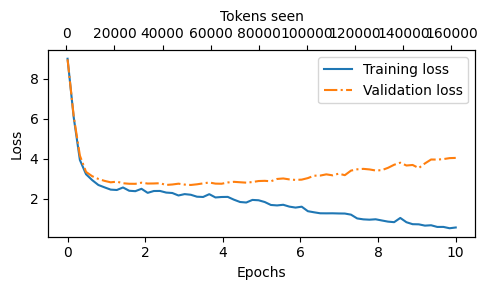

손실 곡선 저장/표시 완료


In [32]:
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator

def plot_losses(epochs_seen, tokens_seen, train_losses, val_losses):
    fig, ax1 = plt.subplots(figsize=(5, 3))
    ax1.plot(epochs_seen, train_losses, label="Training loss")
    ax1.plot(epochs_seen, val_losses, linestyle="-.", label="Validation loss")
    ax1.set_xlabel("Epochs")
    ax1.set_ylabel("Loss")
    ax1.legend(loc="upper right")
    ax1.xaxis.set_major_locator(MaxNLocator(integer=True))

    ax2 = ax1.twiny()   # y축을 공유하는 두 번째 x축 (토큰 수)
    ax2.plot(tokens_seen, train_losses, alpha=0)   # 눈금 정렬용 투명 그래프
    ax2.set_xlabel("Tokens seen")

    fig.tight_layout()
    plt.savefig("loss-plot.png")   # Colab에서는 plt.show()로 바로 표시됨
    plt.show()

epochs_tensor = torch.linspace(0, num_epochs, len(train_losses))
plot_losses(epochs_tensor, tokens_seen, train_losses, val_losses)
print("손실 곡선 저장/표시 완료")

### 실험 결과 해석

- 훈련 전 손실 : **훈련 11.0142 / 검증 10.9930**
- 10에포크 마지막 평가 손실 : **훈련 0.553 / 검증 4.039**
- 초기 구간에서는 두 손실이 함께 감소하였으나, 약 3~4에포크 이후 훈련 손실과 검증 손실의 차이가 점차 확대됨.
- 훈련 손실이 지속적으로 낮아지는 반면 검증 손실은 이후 상승하여 **과적합 징후**가 관찰됨.
- 생성 텍스트에는 불완전한 한국어 조합과 `�`가 포함되어 **문장 품질의 한계**가 나타남. 영어 중심 GPT-2 토크나이저, 무작위 초기화 모델, 제한된 한국어 학습 데이터가 영향을 미쳤을 가능성이 있음.
- 이는 금융 분야 지식의 정확성이나 환각 감소 효과를 검증한 결과가 아니라 **언어 모델 훈련의 한계를 관찰한 결과**임.


### 체크포인트 저장 — ch09로 인계

훈련한 모델과 옵티마이저 상태를 저장합니다 (원본 5.4절에서 배울 저장·로드의 예고편).
다음 챕터(ch09)의 노트북이 이 파일을 발견하면 **방금 훈련한 모델**로 디코딩 실습을 이어갑니다.

> Colab은 노트북마다 가상 머신이 분리되므로, 이어서 실습하려면 아래 파일을
> 내려받아 ch09 노트북에 업로드하거나 Google Drive에 복사해 두세요.
> (없어도 ch09는 랜덤 초기화 모델로 정상 진행됩니다.)

In [33]:
# 모델 + 옵티마이저 상태 저장 (원본 5.4절 방식)
torch.save(
    {
        "model_state_dict": model.state_dict(),
        "optimizer_state_dict": optimizer.state_dict(),
    },
    "model_and_optimizer.pth"
)
print("체크포인트 저장 완료: model_and_optimizer.pth")
print("-> ch09 노트북이 같은 폴더에서 이 파일을 발견하면 훈련된 모델로 이어서 실습합니다.")

체크포인트 저장 완료: model_and_optimizer.pth
-> ch09 노트북이 같은 폴더에서 이 파일을 발견하면 훈련된 모델로 이어서 실습합니다.


## 실습 정리

1. **학습 데이터 :** NIA 및 금융위원회 공식 자료의 관련 본문을 추출·정제해 21,360바이트, 18,253 GPT-2 토큰의 한국어 텍스트 구축.
2. **학습 방식 :** GPT 모델 무작위 초기화, 훈련·검증 데이터 90:10 분할, GPU에서 AdamW로 10에포크 훈련.
3. **초기 손실 :** 훈련 11.0142 / 검증 10.9930.
4. **최종 기록 손실 :** 훈련 0.553 / 검증 4.039 (10에포크 마지막 평가 시점).
5. **분석 :** 초기에는 두 손실이 감소하였으나 이후 검증 손실이 증가하여 과적합 징후 확인. 생성 텍스트의 한국어 품질도 낮음.
6. **한계 :** 본 실험은 작은 한국어 자료로 학습한 GPT의 생성·일반화 특성을 관찰하는 실습이며, 금융 AI 챗봇이나 RAG 기반 환각 방지 기능을 구현한 것은 아님.
7. **결과물 :** 손실 그래프(`loss-plot.png`) 및 모델 상태 체크포인트(`model_and_optimizer.pth`) 저장.

**자료 출처**
- 한국지능정보사회진흥원(NIA), 「검색증강생성(RAG) 기술의 등장과 발전 동향」, Digital Insight 2024.
- 금융위원회, 「금융 특화 AI 개발의 밑거름을 제공하겠습니다」, 2025.03.31.
